# Marketing Analytics - Ulta Blush Shades
**Business context:** A blush brand's marketing claims ("shades for everyone") depend on which color-season customers the range actually serves, and how different the palette is from competitors'.

**Questions**
1. Which color seasons does each brand serve, and who is under-serving winter and autumn customers?
2. Which brands have the most distinctive palettes, and which are near-duplicates of each other? (distance in LAB space)
3. What can be built from this data?

**Data:** `Ulta_Blush_HEX_Codes.csv` (one row per shade: brand, product, hex swatch color, color season). No sales, price, or ratings, so findings are about assortment, not revenue.
**Tools:** Python (pandas, scipy, seaborn) -> CSV exports -> Tableau dashboard.

## Setup & cleaning

In [25]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.spatial import cKDTree
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.95)
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
os.makedirs("tableau_exports", exist_ok=True)
MIN_N = 15          # minimum shades for a brand to be analyzed
SEASON_ORDER = ["light spring","bright/clear spring","true/warm spring",
                "light summer","soft summer","true/cool summer",
                "soft autumn","true/warm autumn","dark/deep autumn",
                "true/cool winter","bright/clear winter","dark/deep winter"]

In [26]:
# color science helpers (sRGB -> CIELAB, D65)
M = np.array([[0.4124564,0.3575761,0.1804375],[0.2126729,0.7151522,0.0721750],[0.0193339,0.1191920,0.9503041]])
WHITE = np.array([0.95047, 1.0, 1.08883])

def hex_to_rgb(h):
    h = h.lstrip("#"); return [int(h[i:i+2], 16) for i in (0, 2, 4)]

def rgb_to_lab(rgb):
    c = np.asarray(rgb, float) / 255
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    xyz = (c @ M.T) / WHITE
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.c_[116 * f[:, 1] - 16, 500 * (f[:, 0] - f[:, 1]), 200 * (f[:, 1] - f[:, 2])]

def lab_to_linear_rgb(lab):
    lab = np.asarray(lab, float)
    fy = (lab[:, 0] + 16) / 116
    f = np.c_[fy + lab[:, 1] / 500, fy, fy - lab[:, 2] / 200]
    xyz = np.where(f ** 3 > 0.008856, f ** 3, (f - 16 / 116) / 7.787) * WHITE
    return xyz @ np.linalg.inv(M).T

def lab_to_hex(lab):
    lin = np.clip(lab_to_linear_rgb(lab), 0, 1)
    c = np.where(lin > 0.0031308, 1.055 * lin ** (1 / 2.4) - 0.055, 12.92 * lin)
    return ["#%02x%02x%02x" % tuple(np.round(r * 255).astype(int)) for r in c]

def delta_e(a, b):
    """CIE76 delta-E: Euclidean distance in LAB. ~2.3 = just-noticeable difference."""
    return np.linalg.norm(np.asarray(a) - np.asarray(b), axis=-1)

In [27]:
DATA_FILE = "Ulta_Blush_HEX_Codes.csv"     
try:
    raw = pd.read_csv(DATA_FILE, encoding="utf-8-sig")   # utf-8-sig also strips a BOM if Excel added one
except UnicodeDecodeError:
    raw = pd.read_csv(DATA_FILE, encoding="cp1252")
df = raw.rename(columns={"product url":"product_url","swatch alt":"swatch_alt","swatch image url":"swatch_img",
                         "dominant color 1":"hex","dominant color 2":"hex2","Season Type":"season"}).copy()
print("raw rows:", len(df))

# 1) recover missing product names from the product URL slug
slug = df.product_url.str.extract(r"/p/(.+?)-[a-zA-Z]*prod\d+")[0]
bad_name = df["name"].isna() | df["name"].astype(str).str.match(r"^(Err:|#ERROR|#N/A|#REF)")   # spreadsheet error cells
df["product"] = df["name"].where(~bad_name, slug.str.replace("-", " ").str.title())
print("product names still missing:", df["product"].isna().sum())

# 2) tidy text, drop exact duplicate swatches
df["brand"] = df["brand"].str.strip()
df["hex"] = df["hex"].str.lower().str.strip()
before = len(df)
df = df.drop_duplicates(subset=["brand", "swatch_alt", "hex"]).reset_index(drop=True)
print("duplicate swatches removed:", before - len(df))

# 3) dominant color 2 is mostly pure red (#fe0000 / #ff0000) -> extraction artifact, so only color 1 is used
print("share of hex2 that is near-pure red:", df.hex2.str.match(r"^#f[c-f]0[0-3]0[0-3]$").mean().round(2))
df = df.drop(columns=["hex2", "name"])

# 4) season family + LAB / LCh coordinates
df["family"] = df.season.str.extract(r"(spring|summer|autumn|winter)")[0]
df["season"] = pd.Categorical(df.season, SEASON_ORDER, ordered=True)
lab = rgb_to_lab([hex_to_rgb(h) for h in df.hex])
df[["L", "a", "b"]] = lab
df["C"] = np.hypot(df.a, df.b)                       # chroma
df["h"] = np.degrees(np.arctan2(df.b, df.a)) % 360   # hue angle
print("clean rows:", len(df), "| brands:", df.brand.nunique(), "| products:", df["product"].nunique())
df.head()

raw rows: 1405
product names still missing: 0
duplicate swatches removed: 119
share of hex2 that is near-pure red: 0.42
clean rows: 1286 | brands: 77 | products: 233


,product_url,shade,swatch_alt,brand,swatch_img,hex,season,product,family,L,a,b,C,h
0,https://www.ulta.com/p/cheek-freak-blush-balm-...,Big O,Big O Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2599828_sw?img40...,#842e39,dark/deep autumn,Cheek Freak Blush Balm,autumn,32.160294,37.777364,13.077085,39.976735,19.093906
1,https://www.ulta.com/p/cheek-freak-blush-balm-...,Champagne Room,Champagne Room Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2607795_sw?img40...,#f6586c,bright/clear spring,Cheek Freak Blush Balm,spring,59.581105,61.613274,22.206260,65.492850,19.819850
2,https://www.ulta.com/p/cheek-freak-blush-balm-...,Cowgirl,Cowgirl Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2599860_sw?img40...,#c0483d,bright/clear spring,Cheek Freak Blush Balm,spring,47.211762,47.468808,31.934036,57.210754,33.930192
3,https://www.ulta.com/p/cheek-freak-blush-balm-...,Get Some,Get Some Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2619149_sw?img40...,#a83f53,true/cool winter,Cheek Freak Blush Balm,winter,42.010482,44.794443,11.096037,46.148284,13.912694
4,https://www.ulta.com/p/cheek-freak-blush-balm-...,Laid,Laid Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2619150_sw?img40...,#fe708b,light summer,Cheek Freak Blush Balm,summer,65.380352,56.400153,12.551103,57.779819,12.545976


## 1. Which color seasons does each brand serve?
**Metrics (per brand with at least `MIN_N` shades)**
- *Winter+Autumn share*: share of the brand's shades labeled winter or autumn, compared with the market baseline.
- *One-sided binomial test*: is that share lower than the market baseline by more than chance?
- *Season Coverage Score*: average of (a) share of the 12 season types present and (b) evenness (normalized Shannon entropy) of the shade mix.

In [28]:
fam_order = ["spring","summer","autumn","winter"]
print("Market share by season family:"); print(df.family.value_counts(normalize=True).reindex(fam_order).round(3).to_string())
market_wa = df.family.isin(["winter","autumn"]).mean()
print(f"\nMarket baseline, winter+autumn share: {market_wa:.1%}")

from scipy.stats import binomtest, entropy
rows = []
for brand, g in df.groupby("brand"):
    n = len(g)
    if n < MIN_N: continue
    k = g.family.isin(["winter","autumn"]).sum()
    counts = g.season.value_counts().reindex(SEASON_ORDER, fill_value=0)
    cover = (counts > 0).mean()
    even = entropy(counts[counts > 0]) / np.log(12)
    rows.append(dict(brand=brand, n_shades=n, winter_share=(g.family=="winter").mean(), autumn_share=(g.family=="autumn").mean(),
                     wa_share=k/n, wa_gap_pts=(k/n-market_wa)*100,
                     p_under=binomtest(k, n, market_wa, alternative="less").pvalue,
                     seasons_covered=int((counts>0).sum()), evenness=even, coverage_score=0.5*cover+0.5*even))
brand_scores = pd.DataFrame(rows).sort_values("wa_share").reset_index(drop=True)
brand_scores["underserving_flag"] = (brand_scores.p_under < 0.10)
print(f"\nBrands analyzed: {len(brand_scores)} (>= {MIN_N} shades)")
brand_scores.round(3)

Market share by season family:
family
spring    0.630
summer    0.123
autumn    0.155
winter    0.093

Market baseline, winter+autumn share: 24.7%

Brands analyzed: 37 (>= 15 shades)


,brand,n_shades,winter_share,autumn_share,wa_share,wa_gap_pts,p_under,seasons_covered,evenness,coverage_score,underserving_flag
0,Maybelline,18,0.000,0.000,0.000,-24.728,0.006,4,0.404,0.368,True
1,KIKO Milano,17,0.000,0.059,0.059,-18.845,0.053,5,0.351,0.384,True
2,bareMinerals,34,0.000,0.088,0.088,-15.904,0.018,5,0.338,0.378,True
3,Revolution Beauty,40,0.075,0.025,0.100,-14.728,0.018,7,0.586,0.585,True
4,RMS Beauty,18,0.000,0.111,0.111,-13.617,0.141,6,0.511,0.506,False
5,ULTA Beauty Collection,45,0.022,0.089,0.111,-13.617,0.020,10,0.611,0.722,True
6,Morphe,18,0.056,0.056,0.111,-13.617,0.141,6,0.594,0.547,False
7,ColourPop,23,0.043,0.087,0.130,-11.684,0.143,6,0.533,0.516,False
8,Stila,15,0.067,0.067,0.133,-11.395,0.244,5,0.538,0.478,False
9,CHANEL,27,0.037,0.111,0.148,-9.913,0.166,7,0.618,0.601,False


### Who under-serves winter and autumn customers?

5 brands flagged (winter+autumn share significantly below the market, p < 0.10):


,brand,n_shades,wa_share,wa_gap_pts,winter_share,autumn_share,p_under
0,Maybelline,18,0.000,-24.728,0.000,0.000,0.006
1,KIKO Milano,17,0.059,-18.845,0.000,0.059,0.053
2,bareMinerals,34,0.088,-15.904,0.000,0.088,0.018
3,Revolution Beauty,40,0.100,-14.728,0.075,0.025,0.018
5,ULTA Beauty Collection,45,0.111,-13.617,0.022,0.089,0.020


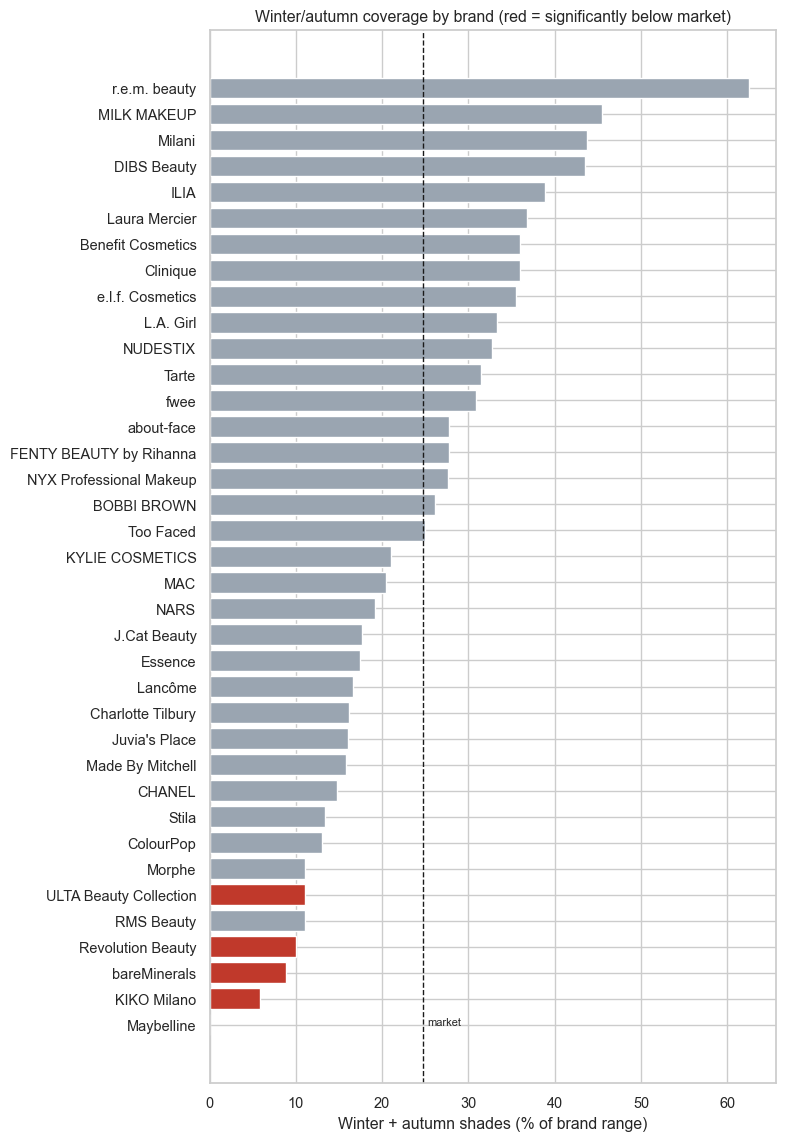

In [29]:
under = brand_scores[brand_scores.underserving_flag].sort_values("wa_gap_pts")
print(f"{len(under)} brands flagged (winter+autumn share significantly below the market, p < 0.10):")
display(under[["brand","n_shades","wa_share","wa_gap_pts","winter_share","autumn_share","p_under"]].round(3))

plot = brand_scores.sort_values("wa_share")
fig, ax = plt.subplots(figsize=(8, 0.28*len(plot)+1.2))
ax.barh(plot.brand, plot.wa_share*100, color=np.where(plot.underserving_flag, "#c0392b", "#9aa5b1"))
ax.axvline(market_wa*100, color="k", ls="--", lw=1); ax.text(market_wa*100+0.5, 0, "market", fontsize=8)
ax.set_xlabel("Winter + autumn shades (% of brand range)"); ax.set_title("Winter/autumn coverage by brand (red = significantly below market)")
plt.tight_layout(); plt.show()

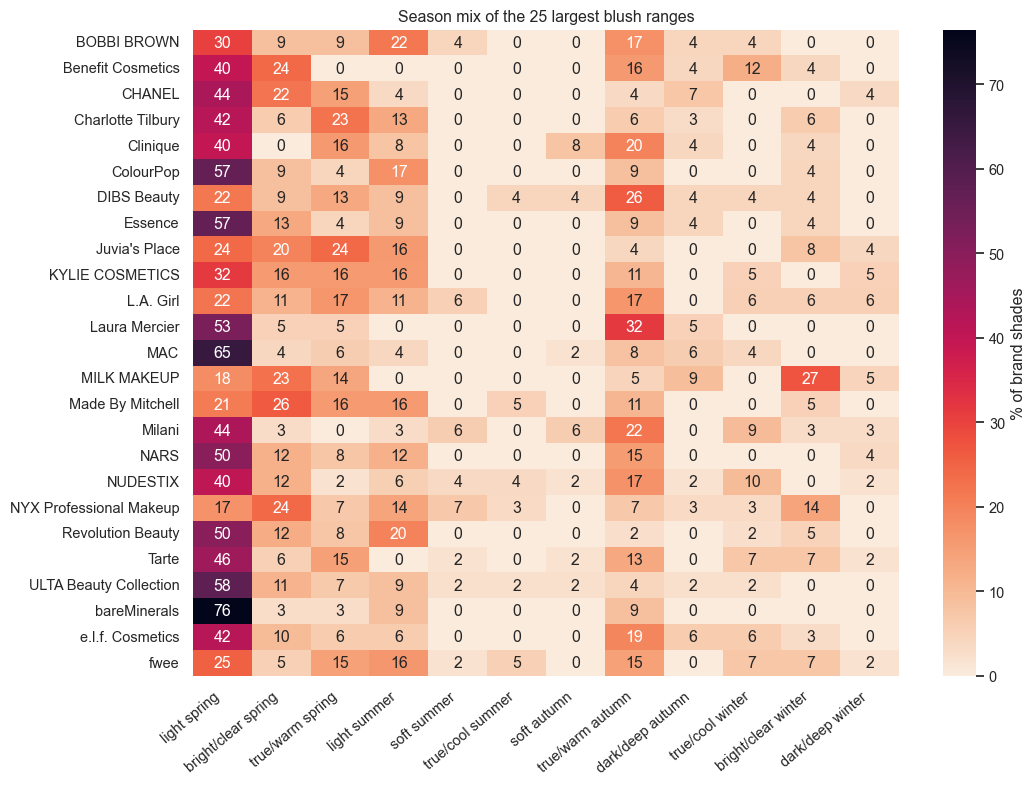

In [30]:
top = brand_scores.sort_values("n_shades", ascending=False).head(25).brand
heat = pd.crosstab(df[df.brand.isin(top)].brand, df.season, normalize="index").reindex(columns=SEASON_ORDER)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(heat*100, cmap="rocket_r", annot=True, fmt=".0f", cbar_kws={"label":"% of brand shades"}, ax=ax)
ax.set_title("Season mix of the 25 largest blush ranges"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

**How to read this:** most of the market is spring-labeled, so winter and autumn are the scarce customer groups. Brands flagged in red are where a campaign claiming inclusivity is hardest to support. Brands with a high coverage score are the benchmark.

## 2. Which brands have distinctive palettes, and which are near-duplicates?
**Method:** For every brand pair, compute a symmetric palette distance: for each shade in brand A find its nearest shade in brand B (ΔE in LAB space), average those distances, do the same from B to A, and average the two directions. Small distance = overlapping palettes.

**Distinctiveness** = a brand's average palette distance to all other brands.
*Note: ΔE76 (Euclidean LAB distance) is used for transparency. ΔE of about 2.3 is a just-noticeable difference.*

In [31]:
brands = list(brand_scores.brand)
LAB = {b: df.loc[df.brand==b, ["L","a","b"]].values for b in brands}
TREE = {b: cKDTree(LAB[b]) for b in brands}

def palette_distance(A, B):
    dAB = TREE[B].query(LAB[A])[0].mean(); dBA = TREE[A].query(LAB[B])[0].mean()
    return (dAB + dBA) / 2

D = pd.DataFrame(0.0, index=brands, columns=brands)
for i, A in enumerate(brands):
    for B in brands[i+1:]:
        D.loc[A, B] = D.loc[B, A] = palette_distance(A, B)

dist = pd.DataFrame({"brand": brands,
                     "distinctiveness": [D.loc[b, [x for x in brands if x != b]].mean() for b in brands],
                     "nearest_brand": [D.loc[b, [x for x in brands if x != b]].idxmin() for b in brands],
                     "nearest_dist": [D.loc[b, [x for x in brands if x != b]].min() for b in brands]})
dist = dist.merge(brand_scores[["brand","n_shades"]], on="brand").sort_values("distinctiveness", ascending=False)
print("Most distinctive palettes:"); display(dist.head(8).round(2))
print("Least distinctive (most generic) palettes:"); display(dist.tail(8).round(2))

Most distinctive palettes:


,brand,distinctiveness,nearest_brand,nearest_dist,n_shades
15,J.Cat Beauty,13.63,Tarte,10.95,17
35,MILK MAKEUP,12.58,Tarte,8.84,22
10,Made By Mitchell,12.53,ULTA Beauty Collection,10.18,19
23,about-face,12.39,Revolution Beauty,9.88,18
19,Too Faced,12.17,KYLIE COSMETICS,9.37,16
0,Maybelline,12.13,bareMinerals,7.86,18
36,r.e.m. beauty,11.80,Tarte,7.89,16
8,Stila,11.55,CHANEL,8.66,15


Least distinctive (most generic) palettes:


,brand,distinctiveness,nearest_brand,nearest_dist,n_shades
32,ILIA,9.50,Tarte,7.19,18
5,ULTA Beauty Collection,9.45,MAC,7.49,45
12,Charlotte Tilbury,9.42,RMS Beauty,7.36,31
20,BOBBI BROWN,9.38,Tarte,6.94,23
28,e.l.f. Cosmetics,9.08,Tarte,7.11,31
26,NUDESTIX,9.08,Milani,7.22,52
24,fwee,9.00,Tarte,6.54,55
25,Tarte,8.37,fwee,6.54,54


Near-duplicate brand pairs (smallest palette distance):


,brand_a,brand_b,palette_distance
588,fwee,Tarte,6.54
603,Tarte,Clinique,6.90
534,BOBBI BROWN,Tarte,6.94
500,KYLIE COSMETICS,fwee,6.97
602,Tarte,e.l.f. Cosmetics,7.11
606,Tarte,ILIA,7.19
618,NUDESTIX,Milani,7.22
303,CHANEL,Tarte,7.27
612,NUDESTIX,e.l.f. Cosmetics,7.28
41,KIKO Milano,ColourPop,7.33


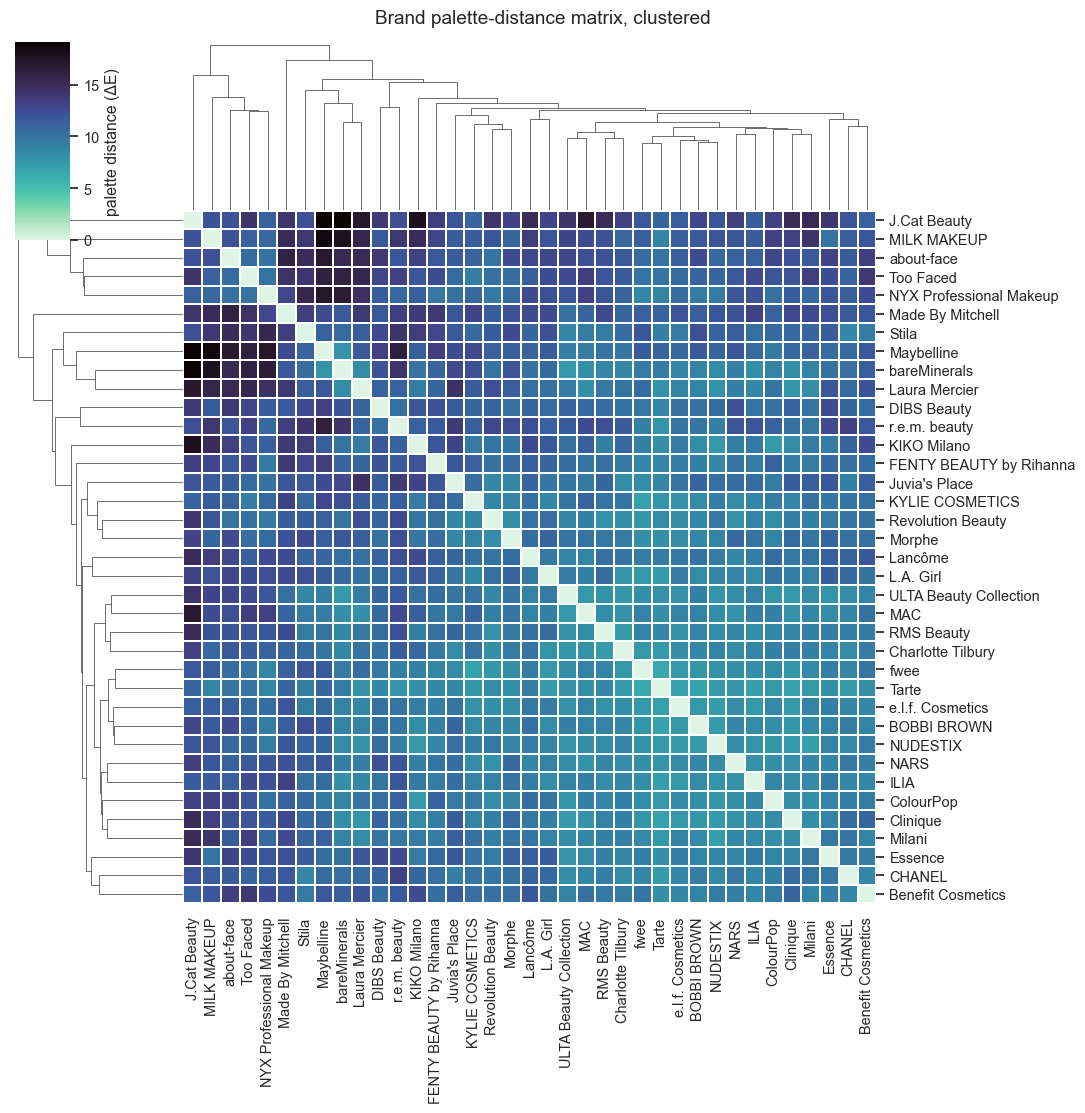

In [32]:
pairs = [(A, B, D.loc[A, B]) for i, A in enumerate(brands) for B in brands[i+1:]]
pairs = pd.DataFrame(pairs, columns=["brand_a","brand_b","palette_distance"]).sort_values("palette_distance")
print("Near-duplicate brand pairs (smallest palette distance):"); display(pairs.head(10).round(2))

g = sns.clustermap(D, cmap="mako_r", figsize=(11, 11), linewidths=0.2, cbar_kws={"label":"palette distance (ΔE)"})
g.fig.suptitle("Brand palette-distance matrix, clustered", y=1.01); plt.show()

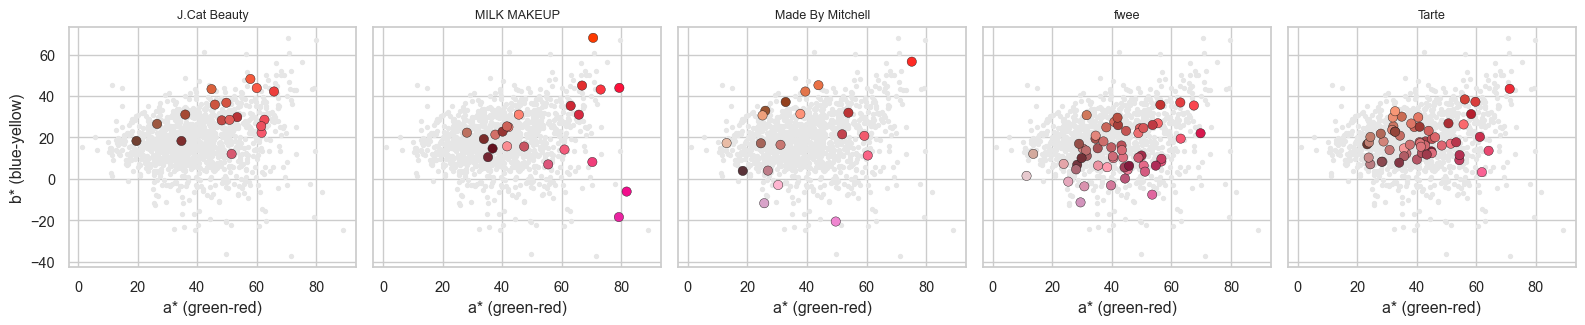

In [33]:
# Palette fingerprint: each brand's shades in the a*-b* plane, using the true swatch colors
sel = list(dist.head(3).brand) + list(pairs.iloc[0][["brand_a","brand_b"]])
sel = list(dict.fromkeys(sel))
fig, axes = plt.subplots(1, len(sel), figsize=(3.2*len(sel), 3.4), sharex=True, sharey=True)
for ax, b in zip(np.atleast_1d(axes), sel):
    g = df[df.brand == b]; ax.scatter(df.a, df.b, c="#e6e6e6", s=8)
    ax.scatter(g.a, g.b, c=g.hex, s=45, edgecolor="k", lw=0.3); ax.set_title(b, fontsize=9)
    ax.set_xlabel("a* (green-red)")
np.atleast_1d(axes)[0].set_ylabel("b* (blue-yellow)"); plt.tight_layout(); plt.show()

**Note:** nearest-neighbor distance is partly size-dependent, since a brand with many shades covers more of the color space. Averaging both directions reduces that effect, but check `n_shades` before calling a small brand "distinctive".

## 3. What can be built from this data?
Three concrete products, each prototyped below, and the Tableau dashboard they feed.

In [15]:
# (a) Dupe finder: for any shade, the closest shades from OTHER brands
def dupe_finder(brand, shade_query, k=5):
    me = df[(df.brand == brand) & df.swatch_alt.str.contains(shade_query, case=False, regex=False)].iloc[0]
    others = df[df.brand != brand].copy()
    others["delta_e"] = delta_e(others[["L","a","b"]].values, me[["L","a","b"]].values.astype(float))
    return me, others.nsmallest(k, "delta_e")[["brand","swatch_alt","hex","season","delta_e"]]

ex_brand = brand_scores.sort_values("n_shades", ascending=False).brand.iloc[0]
me, out = dupe_finder(ex_brand, df[df.brand==ex_brand].swatch_alt.iloc[0])
print(f"Closest matches to: {me.swatch_alt} ({me.hex}, {me.season})"); display(out.round(2))

Closest matches to: ND03 Without Lip&Cheek Blurry Pudding Pot (#ce7f7c, light spring)


,brand,swatch_alt,hex,season,delta_e
558,KIKO Milano,06 Unlimited Blush,#cb7c7b,light spring,1.49
55,bareMinerals,Call My Blush GEN NUDE Powder Blush,#d2807b,light spring,1.97
330,Essence,Rosy Rosewood Pure Nude Baked Blush,#ca7a7b,light spring,2.64
190,Clinique,Berry Delight Blushing Blush Powder Blush,#d68182,light spring,3.27
240,CoverGirl,Sweet Seduction TruBlend So Flushed High Pigme...,#cc847f,light spring,3.29


In [34]:
# (b) Season shopping guide: top shades for a customer season, ranked by brand coverage of that season
def season_guide(season, k=6):
    s = df[df.season == season]
    best = s.groupby("brand").size().sort_values(ascending=False).head(k)
    return best.rename("shades_in_season").to_frame()
print("Best-stocked brands for true/cool winter customers:"); display(season_guide("true/cool winter"))
print("Best-stocked brands for true/warm autumn customers:"); display(season_guide("true/warm autumn"))

Best-stocked brands for true/cool winter customers:


,shades_in_season
brand,
NUDESTIX,5
fwee,4
Tarte,4
Benefit Cosmetics,3
Milani,3
MAC,2


Best-stocked brands for true/warm autumn customers:


,shades_in_season
brand,
NUDESTIX,9
fwee,8
Tarte,7
Milani,7
Laura Mercier,6
e.l.f. Cosmetics,6


,brand,n_shades,coverage_score,distinctiveness,wa_share,positioning
21,NYX Professional Makeup,29,0.84,11.53,0.28,Broad & distinctive
26,NUDESTIX,52,0.83,9.08,0.33,Broad but generic
33,DIBS Beauty,23,0.83,11.18,0.43,Broad & distinctive
24,fwee,55,0.83,9.00,0.31,Broad but generic
27,L.A. Girl,18,0.79,10.28,0.33,Broad & distinctive
19,Too Faced,16,0.78,12.17,0.25,Broad & distinctive
23,about-face,18,0.73,12.39,0.28,Broad & distinctive
5,ULTA Beauty Collection,45,0.72,9.45,0.11,Broad but generic
34,Milani,32,0.72,9.84,0.44,Broad but generic
36,r.e.m. beauty,16,0.71,11.80,0.62,Broad & distinctive


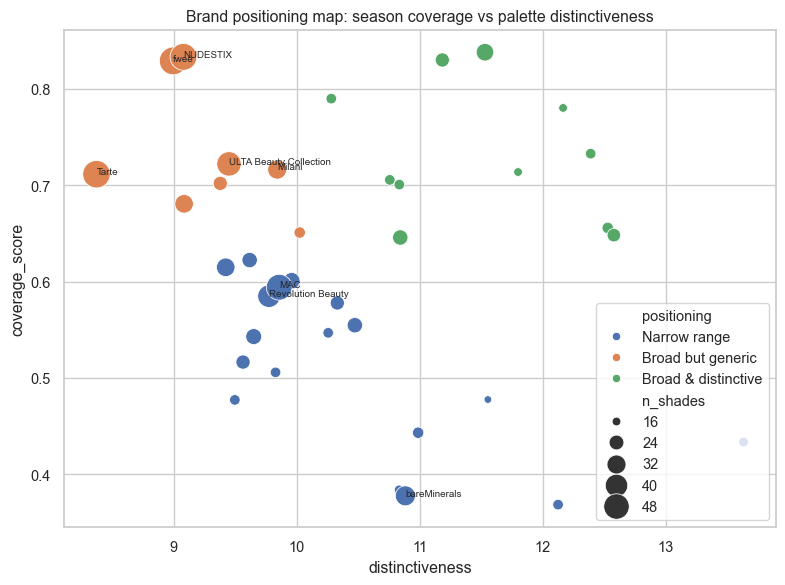

In [19]:
# (c) Brand scorecard for a marketing team: coverage + distinctiveness in one table
scorecard = brand_scores.merge(dist[["brand","distinctiveness","nearest_brand","nearest_dist"]], on="brand")
scorecard["positioning"] = np.select(
    [(scorecard.coverage_score >= scorecard.coverage_score.median()) & (scorecard.distinctiveness >= scorecard.distinctiveness.median()),
     (scorecard.coverage_score >= scorecard.coverage_score.median())],
    ["Broad & distinctive", "Broad but generic"], default="Narrow range")
display(scorecard[["brand","n_shades","coverage_score","distinctiveness","wa_share","positioning"]].sort_values("coverage_score", ascending=False).round(2).head(15))
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=scorecard, x="distinctiveness", y="coverage_score", size="n_shades", hue="positioning", sizes=(30, 400), ax=ax)
for _, r in scorecard.nlargest(8, "n_shades").iterrows(): ax.annotate(r.brand, (r.distinctiveness, r.coverage_score), fontsize=7)
ax.set_title("Brand positioning map: season coverage vs palette distinctiveness"); plt.tight_layout(); plt.show()

### Other things this data can support
- **Interactive "find your season" blush finder** (Tableau or web): pick a season, see swatches across brands.
- **Inclusivity audit / PR claim checker:** scorecard flags brands whose winter and autumn coverage does not match their marketing.
- **Competitive-positioning map:** the quadrant chart above shows which brands crowd each other.
- **Campaign targeting:** put promotion spend behind well-stocked brands for scarce seasons.

## 4. Export for Tableau

In [20]:
shades_out = df[["brand","product","swatch_alt","hex","season","family","L","a","b","C","h","product_url"]]
shades_out.to_csv("tableau_exports/shades_lab.csv", index=False)
bs = pd.crosstab(df.brand, df.season).reindex(columns=SEASON_ORDER).stack().rename("shades").reset_index()
bs["share_of_brand"] = bs.shades / bs.groupby("brand").shades.transform("sum")
bs["family"] = bs.season.str.extract(r"(spring|summer|autumn|winter)")[0]
bs.to_csv("tableau_exports/brand_season_coverage.csv", index=False)
scorecard.to_csv("tableau_exports/brand_scorecard.csv", index=False)
D.stack().rename("palette_distance").rename_axis(["brand_a","brand_b"]).reset_index().to_csv("tableau_exports/brand_palette_distance.csv", index=False)
print(os.listdir("tableau_exports"))

['brand_palette_distance.csv', 'brand_season_coverage.csv', 'shades_lab.csv', 'brand_scorecard.csv']


## 5. Findings summary
- **Market baseline:** 25% of shades are winter or autumn. Of the 37 brands with at least 15 shades, 5 fall significantly below that (p < 0.10): Maybelline, KIKO Milano, bareMinerals, Revolution Beauty and ULTA Beauty Collection.   
- **Best/worst coverage:** No brand covers all 12 seasons. NUDESTIX comes closest at 11, and NYX, fwee, DIBS Beauty and ULTA Beauty Collection cover 10.  
Maybelline has 0% winter and 0% autumn shades and covers only 4 of the 12 seasons.  
bareMinerals, KIKO Milano, RMS Beauty, Laura Mercier and J.Cat Beauty also have no winter shades.  
- **Distinctive vs generic:** J.Cat Beauty has the most distinctive palette (average palette distance ΔE = 13.6). MILK MAKEUP and Made By Mitchell follow at 12.6 and 12.5.  
fwee and Tarte are the closest pair (ΔE = 6.5).  
Tarte is the most generic brand (ΔE = 8.4 from the others).  
- **Recommendation:** brands under-serving winter/autumn should add shades in the cool-deep and warm-deep regions, which Notebook 2 quantifies.
